## ResNet50 Transfer Learning

In [1]:
from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

from tensorflow.keras.layers import (
    GlobalAveragePooling2D,
    Dense,
    Dropout,
    RandomFlip,
    RandomRotation,
    RandomZoom
)

from tensorflow.keras.models import Model

In [46]:
from pathlib import Path
import tensorflow as tf

PROJECT_PATH = Path.cwd().parent
MODEL_PATH = PROJECT_PATH / "models"

best_model_path = MODEL_PATH / "best_resnet50.keras"

print("Model exists:", best_model_path.exists())
print("Model path:", best_model_path)

Model exists: True
Model path: c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\models\best_resnet50.keras


In [2]:
base_model = ResNet50(
    weights='imagenet',
    include_top=False,
    input_shape=(224, 224, 3)
)

base_model.trainable = False

print("ResNet50 loaded successfully!")

94765736/94765736 ━━━━━━━━━━━━━━━━━━━━ 8s 0us/step
ResNet50 loaded successfully!


In [12]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import tensorflow as tf

from tensorflow.keras.applications import ResNet50
from tensorflow.keras.applications.resnet50 import preprocess_input

# Model layers
from tensorflow.keras.layers import (
    Dense,
    Dropout,
    GlobalAveragePooling2D,
    RandomFlip,
    RandomRotation,
    RandomZoom,
    Lambda
)

from tensorflow.keras.models import Model

from tensorflow.keras.callbacks import (
    EarlyStopping,
    ModelCheckpoint,
    ReduceLROnPlateau
)

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_auc_score,
    roc_curve
)

print("All libraries imported successfully!")
print("TensorFlow version:", tf.__version__)

data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

print("Data augmentation created!")

All libraries imported successfully!
TensorFlow version: 2.21.0
Data augmentation created!


In [13]:
inputs = tf.keras.Input(shape=(224, 224, 3))

# Apply augmentation
x = data_augmentation(inputs)

# ResNet50 preprocessing
x = tf.keras.layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input
)(x)

# Extract features using pretrained ResNet50
x = base_model(x, training=False)

# Classification head
x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    256,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.4)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

resnet_model = tf.keras.Model(
    inputs=inputs,
    outputs=outputs
)

print("ResNet50 architecture created!")

ResNet50 architecture created!


In [14]:
base_model.trainable = False

print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Trainable layers: 0


In [15]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),

    loss="binary_crossentropy",

    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

resnet_model.summary()

Model: "functional_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_3 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_1 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_1 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [16]:
resnet_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

resnet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    "../models/best_resnet50.keras",
    monitor="val_loss",
    save_best_only=True
)

resnet_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=2,
    factor=0.5,
    min_lr=1e-7
)

In [17]:
print("Training dataset:", "train_ds" in globals())
print("Validation dataset:", "val_ds" in globals())
print("Testing dataset:", "test_ds" in globals())
print("ResNet50 model:", "resnet_model" in globals())

Training dataset: False
Validation dataset: False
Testing dataset: False
ResNet50 model: True


In [27]:
import os
from pathlib import Path

print("CURRENT WORKING DIRECTORY:")
print(Path.cwd())

print("\nPROJECT FILES:")
for item in Path.cwd().iterdir():
    print(item.name, "| Directory:", item.is_dir())

print("\nCHECKING DATASET LOCATIONS:")

paths = [
    Path.cwd() / "dataset" / "cell_images",
    Path.cwd().parent / "dataset" / "cell_images",
    Path.cwd() / "cell_images"
]

for p in paths:
    print("\n", p)
    print("Exists:", p.exists())

    if p.exists():
        print("Contents:", [x.name for x in p.iterdir()])

CURRENT WORKING DIRECTORY:
c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\notebooks

PROJECT FILES:
malaria_training.ipynb | Directory: False
ResNet50_Transfer_Learning.ipynb | Directory: False

CHECKING DATASET LOCATIONS:

 c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\notebooks\dataset\cell_images
Exists: False

 c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\dataset\cell_images
Exists: True
Contents: ['Parasitized', 'Uninfected']

 c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\notebooks\cell_images
Exists: False


In [28]:
from pathlib import Path
import pandas as pd

PROJECT_PATH = Path.cwd().parent

DATASET_PATH = PROJECT_PATH / "dataset" / "cell_images"

parasitized_path = DATASET_PATH / "Parasitized"
uninfected_path = DATASET_PATH / "Uninfected"

data = []

for folder, label in [
    (uninfected_path, 0),
    (parasitized_path, 1)
]:
    for img in folder.iterdir():
        if img.suffix.lower() in [".png", ".jpg", ".jpeg"]:
            data.append([str(img), label])

df = pd.DataFrame(data, columns=["filepath", "label"])

print("Total images:", len(df))
print("\nClass distribution:")
print(df["label"].value_counts())
print("\nDataset loaded successfully!")

Total images: 27558

Class distribution:
label
0    13779
1    13779
Name: count, dtype: int64

Dataset loaded successfully!


In [29]:
from sklearn.model_selection import train_test_split

# First split: 70% training, 30% temporary
train_df, temp_df = train_test_split(
    df,
    test_size=0.30,
    random_state=42,
    stratify=df["label"]
)

# Second split: 15% validation, 15% testing
val_df, test_df = train_test_split(
    temp_df,
    test_size=0.50,
    random_state=42,
    stratify=temp_df["label"]
)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))


Training images: 19290
Validation images: 4134
Testing images: 4134


In [30]:
PROJECT_PATH = Path.cwd().parent
RESULTS_PATH = PROJECT_PATH / "results"

RESULTS_PATH.mkdir(exist_ok=True)

train_df.to_csv(RESULTS_PATH / "train_split.csv", index=False)
val_df.to_csv(RESULTS_PATH / "val_split.csv", index=False)
test_df.to_csv(RESULTS_PATH / "test_split.csv", index=False)

print("All dataset splits saved successfully!")

All dataset splits saved successfully!


In [31]:
IMG_SIZE = (224, 224)
BATCH_SIZE = 32

def create_dataset(df, training=False):

    paths = df["filepath"].values
    labels = df["label"].values

    dataset = tf.data.Dataset.from_tensor_slices(
        (paths, labels)
    )

    def load_image(path, label):

        image = tf.io.read_file(path)

        image = tf.image.decode_image(
            image,
            channels=3,
            expand_animations=False
        )

        image.set_shape([None, None, 3])

        image = tf.image.resize(image, IMG_SIZE)
        image = tf.cast(image, tf.float32)

        return image, tf.cast(label, tf.float32)

    dataset = dataset.map(
        load_image,
        num_parallel_calls=tf.data.AUTOTUNE
    )

    if training:
        dataset = dataset.shuffle(1000, seed=42)

    dataset = dataset.batch(BATCH_SIZE)
    dataset = dataset.prefetch(tf.data.AUTOTUNE)

    return dataset

In [32]:
train_ds = create_dataset(train_df, training=True)
val_ds = create_dataset(val_df)
test_ds = create_dataset(test_df)

print("Training dataset created!")
print("Validation dataset created!")
print("Testing dataset created!")

Training dataset created!
Validation dataset created!
Testing dataset created!


In [33]:
for images, labels in train_ds.take(1):
    print("Image shape:", images.shape)
    print("Label shape:", labels.shape)

Image shape: (32, 224, 224, 3)
Label shape: (32,)


In [34]:
from tensorflow.keras.applications import ResNet50

base_model = ResNet50(
    weights="imagenet",
    include_top=False,
    input_shape=(224, 224, 3)
)

print("ResNet50 loaded successfully!")

ResNet50 loaded successfully!


In [35]:
base_model.trainable = False

print("Total layers:", len(base_model.layers))
print("Trainable layers:", sum(
    layer.trainable for layer in base_model.layers
))

Total layers: 175
Trainable layers: 0


In [36]:
data_augmentation = tf.keras.Sequential([
    tf.keras.layers.RandomFlip("horizontal"),
    tf.keras.layers.RandomRotation(0.1),
    tf.keras.layers.RandomZoom(0.1)
])

In [37]:
inputs = tf.keras.Input(shape=(224, 224, 3))

x = data_augmentation(inputs)

x = tf.keras.layers.Lambda(
    tf.keras.applications.resnet50.preprocess_input
)(x)

x = base_model(x, training=False)

x = tf.keras.layers.GlobalAveragePooling2D()(x)

x = tf.keras.layers.Dense(
    256,
    activation="relu"
)(x)

x = tf.keras.layers.Dropout(0.4)(x)

outputs = tf.keras.layers.Dense(
    1,
    activation="sigmoid"
)(x)

resnet_model = tf.keras.Model(inputs, outputs)

print("ResNet50 model created!")

ResNet50 model created!


In [38]:
resnet_model.compile(
    optimizer=tf.keras.optimizers.Adam(
        learning_rate=0.0001
    ),
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

resnet_model.summary()

Model: "functional_5"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer_6 (InputLayer)      │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ sequential_2 (Sequential)       │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lambda_2 (Lambda)               │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ resnet50 (Functional)           │ (None, 7, 7, 2048)     │    23,587,712 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 2048)           │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 256)            │       524,544 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           257 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 24,112,513 (91.98 MB)

 Trainable params: 524,801 (2.00 MB)

 Non-trainable params: 23,587,712 (89.98 MB)

In [39]:
import os

MODEL_PATH = PROJECT_PATH / "models"
MODEL_PATH.mkdir(exist_ok=True)

resnet_early_stop = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss",
    patience=3,
    restore_best_weights=True
)

resnet_checkpoint = tf.keras.callbacks.ModelCheckpoint(
    str(MODEL_PATH / "best_resnet50.keras"),
    monitor="val_loss",
    save_best_only=True
)

resnet_reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_loss",
    patience=2,
    factor=0.5,
    min_lr=1e-7
)

In [40]:
resnet_history = resnet_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    callbacks=[
        resnet_early_stop,
        resnet_checkpoint,
        resnet_reduce_lr
    ]
)

Epoch 1/10


c:\Users\Sanna Sharma\Desktop\Projectml\Malaria_Project\.venv312\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


603/603 ━━━━━━━━━━━━━━━━━━━━ 1134s 2s/step - accuracy: 0.8637 - auc: 0.9379 - loss: 0.3194 - precision: 0.8707 - recall: 0.8543 - val_accuracy: 0.9098 - val_auc: 0.9705 - val_loss: 0.2313 - val_precision: 0.9104 - val_recall: 0.9090 - learning_rate: 1.0000e-04
Epoch 2/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 676s 1s/step - accuracy: 0.9128 - auc: 0.9695 - loss: 0.2233 - precision: 0.9200 - recall: 0.9041 - val_accuracy: 0.9110 - val_auc: 0.9761 - val_loss: 0.2108 - val_precision: 0.9469 - val_recall: 0.8708 - learning_rate: 1.0000e-04
Epoch 3/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 617s 1s/step - accuracy: 0.9235 - auc: 0.9756 - loss: 0.1988 - precision: 0.9306 - recall: 0.9152 - val_accuracy: 0.9262 - val_auc: 0.9788 - val_loss: 0.1976 - val_precision: 0.9113 - val_recall: 0.9444 - learning_rate: 1.0000e-04
Epoch 4/10
603/603 ━━━━━━━━━━━━━━━━━━━━ 610s 1s/step - accuracy: 0.9302 - auc: 0.9777 - loss: 0.1882 - precision: 0.9376 - recall: 0.9217 - val_accuracy: 0.9282 - val_auc: 0.9810 - val_loss: 0.1811

In [41]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix,
    accuracy_score,
    roc_curve,
    roc_auc_score
)

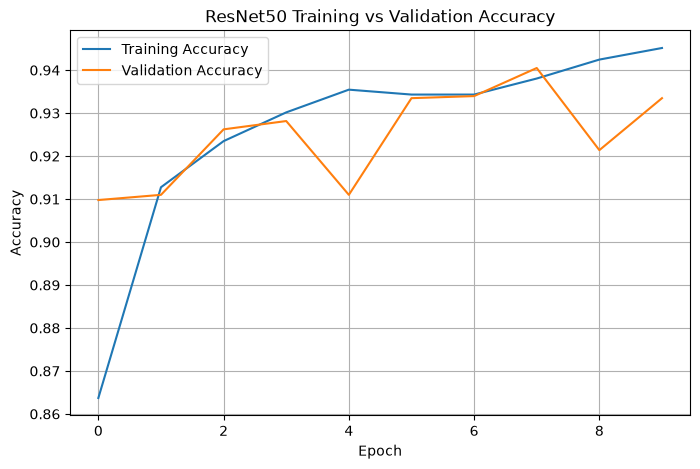

In [42]:
plt.figure(figsize=(8, 5))

plt.plot(
    resnet_history.history["accuracy"],
    label="Training Accuracy"
)

plt.plot(
    resnet_history.history["val_accuracy"],
    label="Validation Accuracy"
)

plt.title("ResNet50 Training vs Validation Accuracy")
plt.xlabel("Epoch")
plt.ylabel("Accuracy")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_PATH / "resnet50_accuracy.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

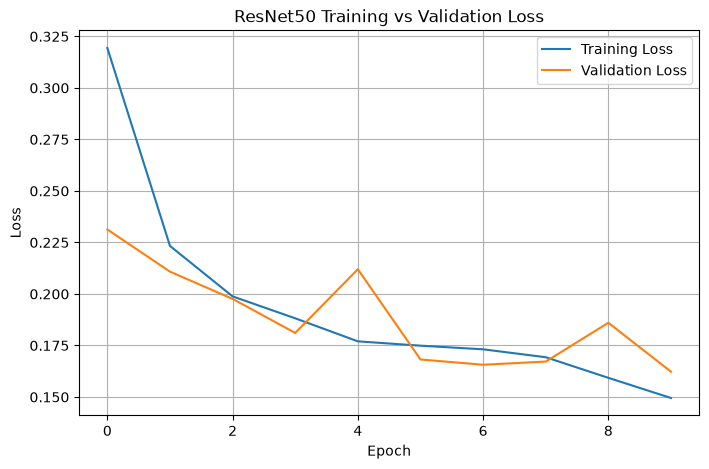

In [43]:
plt.figure(figsize=(8, 5))

plt.plot(
    resnet_history.history["loss"],
    label="Training Loss"
)

plt.plot(
    resnet_history.history["val_loss"],
    label="Validation Loss"
)

plt.title("ResNet50 Training vs Validation Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_PATH / "resnet50_loss.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [51]:
import tensorflow as tf

best_resnet_model = tf.keras.models.load_model(
    best_model_path,
    custom_objects={
        "preprocess_input":
            tf.keras.applications.resnet50.preprocess_input
    },
    safe_mode=False,
    compile=False
)

print("ResNet50 loaded successfully!")

ResNet50 loaded successfully!


In [52]:
best_resnet_model.compile(
    optimizer="adam",
    loss="binary_crossentropy",
    metrics=[
        "accuracy",
        tf.keras.metrics.Precision(name="precision"),
        tf.keras.metrics.Recall(name="recall"),
        tf.keras.metrics.AUC(name="auc")
    ]
)

In [53]:
test_results = best_resnet_model.evaluate(
    test_ds,
    return_dict=True
)

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

130/130 ━━━━━━━━━━━━━━━━━━━━ 145s 1s/step - accuracy: 0.9335 - auc: 0.9845 - loss: 0.1694 - precision: 0.9628 - recall: 0.9018
accuracy: 0.9335
auc: 0.9845
loss: 0.1694
precision: 0.9628
recall: 0.9018


In [54]:
test_results = best_resnet_model.evaluate(
    test_ds,
    return_dict=True
)

print("\nRESNET50 TEST RESULTS")

for metric, value in test_results.items():
    print(f"{metric}: {value:.4f}")

130/130 ━━━━━━━━━━━━━━━━━━━━ 147s 1s/step - accuracy: 0.9335 - auc: 0.9845 - loss: 0.1694 - precision: 0.9628 - recall: 0.9018

RESNET50 TEST RESULTS
accuracy: 0.9335
auc: 0.9845
loss: 0.1694
precision: 0.9628
recall: 0.9018


In [55]:
import numpy as np

y_true = np.concatenate([
    labels.numpy() for images, labels in test_ds
])

y_pred_prob = best_resnet_model.predict(test_ds)

y_pred_prob = y_pred_prob.ravel()

y_pred = (y_pred_prob >= 0.5).astype(int)

print("Predictions generated successfully!")
print("Total predictions:", len(y_pred))

130/130 ━━━━━━━━━━━━━━━━━━━━ 228s 2s/step
Predictions generated successfully!
Total predictions: 4134


In [56]:
from sklearn.metrics import classification_report

print(classification_report(
    y_true,
    y_pred,
    target_names=["Uninfected", "Parasitized"]
))

              precision    recall  f1-score   support

  Uninfected       0.91      0.97      0.94      2067
 Parasitized       0.96      0.90      0.93      2067

    accuracy                           0.93      4134
   macro avg       0.94      0.93      0.93      4134
weighted avg       0.94      0.93      0.93      4134



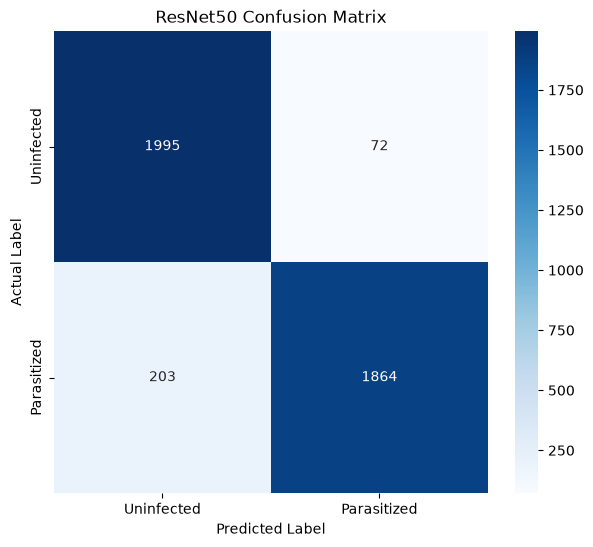

In [57]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

cm = confusion_matrix(y_true, y_pred)

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Uninfected", "Parasitized"],
    yticklabels=["Uninfected", "Parasitized"]
)

plt.title("ResNet50 Confusion Matrix")
plt.xlabel("Predicted Label")
plt.ylabel("Actual Label")

plt.savefig(
    RESULTS_PATH / "resnet50_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

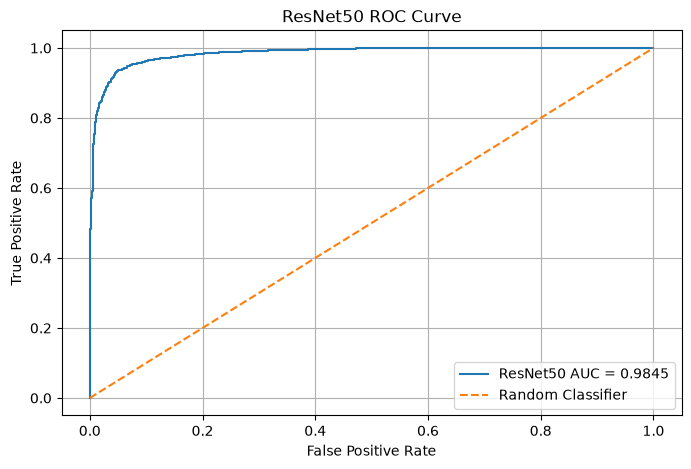

ROC AUC: 0.9844900712441859


In [58]:
from sklearn.metrics import roc_curve, roc_auc_score

fpr, tpr, thresholds = roc_curve(
    y_true,
    y_pred_prob
)

roc_auc = roc_auc_score(
    y_true,
    y_pred_prob
)

plt.figure(figsize=(8, 5))

plt.plot(
    fpr,
    tpr,
    label=f"ResNet50 AUC = {roc_auc:.4f}"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ResNet50 ROC Curve")
plt.legend()
plt.grid(True)

plt.savefig(
    RESULTS_PATH / "resnet50_roc_curve.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("ROC AUC:", roc_auc)

In [59]:
best_resnet_model.save(
    MODEL_PATH / "final_resnet50.keras"
)

print("Final ResNet50 model saved!")

Final ResNet50 model saved!
